<a href="https://colab.research.google.com/github/hawky-t/kovasznay-multistage-pinn/blob/main/kovasznay_pinn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Kovasznay Flow

JAX PINN with one correction stage. Reference: [NSFnets](https://arxiv.org/abs/2003.06496), Section 3.1 and Table 1 (linked v1 preprint).

In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

drive_root = Path('/content/drive/MyDrive/CEE292_PINN')
drive_root.mkdir(parents=True, exist_ok=True)

Mounted at /content/drive


In [ ]:
%pip install -q "flax==0.12.12" "optax==0.2.8" "chex==0.1.90" "toolz==0.12.1" scipy matplotlib jaxtyping
%pip install -q --no-deps "git+https://github.com/haydn-jones/SOAP_JAX@v0.1.0"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## Imports

In [ ]:
from pathlib import Path
from time import perf_counter
import csv
import json

import jax
jax.config.update('jax_enable_x64', True)
import jax.numpy as jnp
from jax.flatten_util import ravel_pytree
from flax import linen as nn, serialization
from importlib.metadata import version
import optax
import numpy as np
from scipy.optimize import minimize
import matplotlib.pyplot as plt

## Problem

In [ ]:
LOWER = jnp.array([-0.5, -0.5])
UPPER = jnp.array([1.0, 1.5])
NU = 1.0 / 40.0
LAMBDA = 1 / (2 * NU) - jnp.sqrt(1 / (4 * NU**2) + 4 * jnp.pi**2)
FIELDS = ('u', 'v', 'p')
EQUATIONS = ('momentum_x', 'momentum_y', 'continuity')
# Jin et al., arXiv:2003.06496v1, Table 1, VP-NSFnet, alpha=100; percentages.
PAPER = {(4, 50): (0.076, 0.412, 0.516),
         (7, 50): (0.038, 0.255, 0.114),
         (7, 100): (0.016, 0.183, 0.062),
         (10, 100): (0.020, 0.115, 0.044),
         (10, 200): (0.012, 0.103, 0.042),
         (10, 250): (0.011, 0.101, 0.031),
         (10, 300): (0.008, 0.072, 0.041)}


def analytical_solution(z):
    x, y = z[..., 0], z[..., 1]
    e = jnp.exp(LAMBDA * x)
    return jnp.stack((1 - e * jnp.cos(2 * jnp.pi * y),
                      LAMBDA / (2 * jnp.pi) * e * jnp.sin(2 * jnp.pi * y),
                      0.5 * (1 - e**2)), axis=-1)


def sample_data(key, N_col, N_bd):
    interior = jax.random.uniform(key, (N_col, 2),
                                  minval=LOWER, maxval=UPPER)
    # Four edges with shared corners counted once: 4*n unique boundary points.
    t = jnp.arange(N_bd) / N_bd
    x = LOWER[0] + t * (UPPER[0] - LOWER[0])
    y = LOWER[1] + t * (UPPER[1] - LOWER[1])
    boundary = jnp.concatenate((
        jnp.stack((x, jnp.full_like(x, LOWER[1])), axis=-1),
        jnp.stack((jnp.full_like(y, UPPER[0]), y), axis=-1),
        jnp.stack((UPPER[0] - (x - LOWER[0]), jnp.full_like(x, UPPER[1])), axis=-1),
        jnp.stack((jnp.full_like(y, LOWER[0]), UPPER[1] - (y - LOWER[1])), axis=-1)))
    return interior, boundary, analytical_solution(boundary)[:, :2]


def residual(field, z):
    q = field(z)
    d = jax.jacfwd(field)(z)
    h = jax.jacfwd(jax.jacfwd(lambda xy: field(xy)[:2]))(z)
    lap = h[:, 0, 0] + h[:, 1, 1]
    momentum = q[0] * d[:2, 0] + q[1] * d[:2, 1] + d[2] - NU * lap
    return jnp.concatenate((momentum, jnp.array([d[0, 0] + d[1, 1]])))

## Model

In [ ]:
class MLP(nn.Module):
    layers: int
    width: int
    zero_output: bool = False
    scl: float = 1.0
    act_s: int = 0

    @nn.compact
    def __call__(self, z):
        h = 2 * (z - LOWER) / (UPPER - LOWER) - 1
        for i in range(self.layers):
            z = self.scl * h if i == 0 else h
            h = nn.Dense(self.width, param_dtype=jnp.float64,
                         kernel_init=nn.initializers.glorot_normal())(z)
            h = jnp.sin(h) if i == 0 and self.act_s == 1 else jnp.tanh(h)
        init = nn.initializers.zeros if self.zero_output else nn.initializers.glorot_normal()
        return nn.Dense(3, param_dtype=jnp.float64, kernel_init=init)(h)


def sol_pred_create(model, epsil=1.0, previous=None):
    def predict(params, z):
        correction = epsil * model.apply(params, z)
        return correction if previous is None else previous(z) + correction
    return predict


def loss_create(pred_u, lw):
    def loss(params, data):
        interior, boundary, target = data
        field = lambda z: pred_u(params, z)
        r = jax.vmap(lambda z: residual(field, z))(interior)
        bc = jnp.mean(jnp.sum((field(boundary)[:, :2] - target)**2, axis=1))
        momentum = jnp.mean(jnp.sum(r[:, :2]**2, axis=1))
        continuity = jnp.mean(r[:, 2]**2)
        terms = jnp.array([bc, momentum, continuity])
        return jnp.dot(lw, terms), terms
    return loss

## Training

In [ ]:
def learning_rate_schedule(lr_strategy, lr, steps, lr_min=1e-6,
                           lr_decay_steps=5000, lr_decay_rate=0.9,
                           decay_steps=(), decay_factors=()):
    if not 0 < lr_min <= lr:
        raise ValueError('Require 0 < lr_min <= lr.')
    if lr_strategy in ('constant', 'plateau'):
        return optax.constant_schedule(lr)
    if lr_strategy == 'cosine':
        return optax.cosine_decay_schedule(lr, steps, alpha=lr_min / lr)
    if lr_strategy in ('exponential', 'step'):
        return optax.exponential_decay(lr, lr_decay_steps, lr_decay_rate,
                                      staircase=(lr_strategy == 'step'), end_value=lr_min)
    if lr_strategy == 'piecewise':
        return optax.piecewise_constant_schedule(lr, dict(zip(decay_steps, decay_factors)))
    raise ValueError(lr_strategy)


def record_loss(evaluate, params, history, method, iteration, start, elapsed,
                learning_rate=None):
    value, terms = evaluate(params)
    value, terms = float(value), np.asarray(terms)
    row = dict(iteration=iteration, seconds=elapsed + perf_counter() - start,
               optimizer=method, total=value, learning_rate=learning_rate)
    row.update(zip(('boundary', 'momentum', 'continuity'), map(float, terms)))
    history.append(row)
    rate_text = "" if learning_rate is None else f" | LR {learning_rate:.3e}"
    print(f"{method:5s} | Step {iteration:6d} | Loss {value:.3e} | "
          f"BC {terms[0]:.3e} | Momentum {terms[1]:.3e} | "
          f"Continuity {terms[2]:.3e}{rate_text}", flush=True)


def _train_optax(lossf, params, data, optimizer_factory, epoch, method, lr=1e-3,
                log_every=100, normalize=False, history=None, lr_strategy='constant',
                lr_min=1e-6, lr_decay_steps=5000, lr_decay_rate=0.9,
                decay_steps=(), decay_factors=(), plateau_factor=0.5,
                plateau_patience=10, plateau_window=100, plateau_rtol=1e-3,
                time_limit=None):
    jax.block_until_ready(params)
    start = perf_counter()
    evaluate = jax.jit(lambda p: lossf(p, data))
    factor = max(float(evaluate(params)[0]), 1e-30) if normalize else 1.0
    objective = lambda p: evaluate(p)[0] / factor

    rate = learning_rate_schedule(
        lr_strategy, lr, epoch, lr_min,
        lr_decay_steps, lr_decay_rate, decay_steps, decay_factors)

    optimizer = optax.with_extra_args_support(optimizer_factory(rate))
    if lr_strategy == 'plateau':
        reducer = optax.contrib.reduce_on_plateau(
            factor=plateau_factor, patience=plateau_patience,
            rtol=plateau_rtol, accumulation_size=plateau_window,
            min_scale=lr_min / lr)
        optimizer = optax.chain(optimizer, reducer)

    state = optimizer.init(params)
    history = list(history or [])
    offset = history[-1]['iteration'] if history else 0
    elapsed = history[-1]['seconds'] if history else 0.0

    @jax.jit
    def step(p, state, count):
        value, g = jax.value_and_grad(objective)(p)
        updates, state = optimizer.update(g, state, p, value=value * factor)
        used_rate = rate(count)
        if lr_strategy == 'plateau':
            used_rate = used_rate * state[-1].scale
        return optax.apply_updates(p, updates), state, used_rate

    record_loss(
        evaluate, params, history, method, offset,
        start, elapsed, float(rate(0)))

    iteration = 0
    used_rate = rate(0)

    # A time limit replaces the update-count stopping condition.
    while True:
        if time_limit is None:
            if iteration >= epoch:
                break
        elif perf_counter() - start >= time_limit:
            break

        params, state, used_rate = step(
            params, state, jnp.asarray(iteration))
        jax.block_until_ready((params, state, used_rate))
        iteration += 1

        if iteration % log_every == 0:
            record_loss(
                evaluate, params, history, method, offset + iteration,
                start, elapsed, float(used_rate))

    if history[-1]['iteration'] != offset + iteration:
        record_loss(
            evaluate, params, history, method, offset + iteration,
            start, elapsed, float(used_rate))

    info = dict(
        optimizer=method,
        updates=iteration,
        seconds=perf_counter() - start,
        time_limit=time_limit,
        schedule_steps=epoch,
        loss_normalization=factor,
        lr=lr,
        lr_strategy=lr_strategy,
        lr_min=lr_min,
        lr_decay_steps=lr_decay_steps,
        lr_decay_rate=lr_decay_rate,
        decay_steps=decay_steps,
        decay_factors=decay_factors)

    if lr_strategy == 'plateau':
        info.update(
            plateau_factor=plateau_factor,
            plateau_patience=plateau_patience,
            plateau_window=plateau_window,
            plateau_rtol=plateau_rtol,
            plateau_metric='unscaled weighted training loss before each update')

    return params, history, info


def train_adam(lossf, params, data, epoch, lr=1e-3, **lr_options):
    return _train_optax(lossf, params, data, optax.adam, epoch, 'adam', lr, **lr_options)


def train_soap(lossf, params, data, epoch, lr=1e-3, **lr_options):
    from soap_jax import soap
    factory = lambda rate: soap(learning_rate=rate, b1=0.9, b2=0.999,
                                weight_decay=0.0, precondition_frequency=1)
    return _train_optax(lossf, params, data, factory, epoch, 'soap', lr, **lr_options)


def train_lbfgs(lossf, params, data, maxiter=50000, log_every=100,
                normalize=False, history=None):
    start = perf_counter()
    evaluate = jax.jit(lambda p: lossf(p, data))
    factor = max(float(evaluate(params)[0]), 1e-30) if normalize else 1.0
    flat, unravel = ravel_pytree(params)
    value_grad = jax.jit(jax.value_and_grad(lambda x: evaluate(unravel(x))[0] / factor))
    history = list(history or [])
    offset = history[-1]['iteration'] if history else 0
    elapsed = history[-1]['seconds'] if history else 0.0

    def objective(x):
        value, g = value_grad(jnp.asarray(x))
        return float(value), np.asarray(g, dtype=np.float64)

    accepted = 0

    def callback(x):
        nonlocal accepted
        accepted += 1
        if accepted % log_every == 0:
            record_loss(evaluate, unravel(jnp.asarray(x)), history, 'lbfgs',
                        offset + accepted, start, elapsed)

    record_loss(evaluate, params, history, 'lbfgs', offset, start, elapsed)
    result = minimize(objective, np.asarray(flat), jac=True, method='L-BFGS-B',
                      callback=callback, options=dict(maxiter=maxiter, maxfun=5 * maxiter,
                      maxls=50, ftol=np.finfo(float).eps, gtol=1e-10))
    params = unravel(jnp.asarray(result.x))
    record_loss(evaluate, params, history, 'lbfgs', offset + result.nit, start, elapsed)
    info = dict(optimizer='lbfgs', maxiter=maxiter, iterations=int(result.nit),
                evaluations=int(result.nfev), success=bool(result.success),
                message=str(result.message), seconds=perf_counter() - start,
                loss_normalization=factor)
    print(result.message)
    return params, history, info

## Results

In [ ]:
def evaluate_stage(predict, params, data, nx=111, ny=111, batch_size=256):
    x = np.linspace(float(LOWER[0]), float(UPPER[0]), nx)
    y = np.linspace(float(LOWER[1]), float(UPPER[1]), ny)
    X, Y = np.meshgrid(x, y)
    z = np.stack((X.ravel(), Y.ravel()), axis=-1)
    field = lambda xy: predict(params, xy)
    predict_batch = jax.jit(jax.vmap(field))
    residual_batch = jax.jit(jax.vmap(lambda xy: residual(field, xy)))
    prediction, equations = [], []
    for i in range(0, len(z), batch_size):
        batch = jnp.asarray(z[i:i + batch_size])
        prediction.append(np.asarray(predict_batch(batch)))
        equations.append(np.asarray(residual_batch(batch)))
    raw = np.concatenate(prediction)
    reference = np.asarray(analytical_solution(jnp.asarray(z)))
    prediction = raw.copy()
    # Match the pressure-mean alignment described before Eq. (9) in the paper.
    shift = float(np.mean(reference[:, 2] - prediction[:, 2]))
    prediction[:, 2] += shift
    error = prediction - reference
    equations = np.concatenate(equations)
    metrics = dict(pressure_shift=shift)
    for j, name in enumerate(FIELDS):
        metrics[name + '_relative_l2'] = float(np.linalg.norm(error[:, j]) /
                                              np.linalg.norm(reference[:, j]))
        metrics[name + '_rmse'] = float(np.sqrt(np.mean(error[:, j]**2)))
    for j, name in enumerate(EQUATIONS):
        metrics[name + '_rms'] = float(np.sqrt(np.mean(equations[:, j]**2)))
    boundary_error = np.asarray(predict_batch(data[1]))[:, :2] - np.asarray(data[2])
    metrics['boundary_velocity_rms'] = float(np.sqrt(np.mean(boundary_error**2)))
    shape = (ny, nx, 3)
    return dict(x=x, y=y, prediction=prediction.reshape(shape),
                raw_prediction=raw.reshape(shape), reference=reference.reshape(shape),
                error=error.reshape(shape), residual=equations.reshape(shape), metrics=metrics)


def paper_comparison(metrics, n_hl, n_unit):
    paper = PAPER.get((n_hl, n_unit))
    rows = []
    for i, name in enumerate(FIELDS):
        ours = 100 * metrics[name + '_relative_l2']
        rows.append(dict(field=name, ours_percent=ours,
                         paper_percent=None if paper is None else paper[i]))
    print(f'\nStage 1: {n_hl} x {n_unit}; relative L2 error (%)')
    print(f'{"Field":<8}{"Ours":>14}{"Paper":>14}')
    for row in rows:
        ref = 'n/a' if row['paper_percent'] is None else f"{row['paper_percent']:.6f}"
        print(f"{row['field']:<8}{row['ours_percent']:>14.6f}{ref:>14}")
    print('Paper: Table 1, VP, alpha=100; each entry is best of ten runs.')
    print('Ours: one seed; current training budget; independent evaluation grid.')
    return rows

## Plots

In [ ]:
def plot_fields(result, title):
    fig, axes = plt.subplots(3, 3, figsize=(10, 9), constrained_layout=True)
    for row, name in enumerate(('prediction', 'error', 'residual')):
        for j in range(3):
            values = result[name][..., j]
            if name == 'error':
                values = np.abs(values)
            image = axes[row, j].pcolormesh(result['x'], result['y'], values,
                                            shading='auto', cmap='viridis')
            label = EQUATIONS[j] if name == 'residual' else FIELDS[j]
            display = 'abs error' if name == 'error' else name
            axes[row, j].set(title=f'{label}: {display}', xlabel='x', ylabel='y')
            fig.colorbar(image, ax=axes[row, j])
    fig.suptitle(title)
    plt.show()
    return fig


def plot_loss(history, title):
    fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
    iterations = [r['iteration'] for r in history]
    for name in ('total', 'boundary', 'momentum', 'continuity'):
        ax.semilogy(iterations, [max(r[name], 1e-30) for r in history], label=name)
    for previous, current in zip(history, history[1:]):
        if previous['optimizer'] != current['optimizer']:
            ax.axvline(current['iteration'], color='gray', linestyle='--',
                       label=current['optimizer'] + ' start')
    ax.set(title=title, xlabel='Iteration', ylabel='Loss')
    ax.legend()
    plt.show()
    return fig


def spectrum(values, dx, dy):
    # Signed fields, mean removed, Hann window: finite-domain diagnostic, not a periodic flow.
    ny, nx, _ = values.shape
    window = np.hanning(ny)[:, None] * np.hanning(nx)[None, :]
    centered = values - np.mean(values, axis=(0, 1), keepdims=True)
    transform = np.fft.fftshift(np.fft.fft2(centered * window[..., None], axes=(0, 1)),
                                axes=(0, 1))
    power = np.abs(transform)**2 / np.sum(window**2)
    return (np.fft.fftshift(np.fft.fftfreq(nx, dx)),
            np.fft.fftshift(np.fft.fftfreq(ny, dy)), power)


def plot_spectrum(result, title, kxlim=(-10, 10), kylim=(-10, 10)):
    dx, dy = np.diff(result['x'])[0], np.diff(result['y'])[0]
    fig, axes = plt.subplots(2, 3, figsize=(10, 6), constrained_layout=True)
    for row, name in enumerate(('error', 'residual')):
        fx, fy, power = spectrum(result[name][:-1, :-1], dx, dy)
        for j in range(3):
            ax = axes[row, j]
            image = ax.pcolormesh(
                fx, fy, np.log10(power[..., j] + 1e-30),
                shading='auto', cmap='magma')
            label = FIELDS[j] if name == 'error' else EQUATIONS[j]
            ax.set(title=f'{label}: {name}',
                   xlabel='kx (cycles/unit)', ylabel='ky (cycles/unit)')
            ax.set_xlim(kxlim)
            ax.set_ylim(kylim)
            fig.colorbar(image, ax=ax, label='log10 power')
    fig.suptitle(title)
    plt.show()
    return fig

## Save

In [ ]:
def write_csv(path, rows):
    with path.open('w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def save_stage(folder, stage, params, result, history, training, data, figures,
               comparison=None, **settings):
    folder = Path(folder) / f'stage{stage}'
    folder.mkdir(parents=True, exist_ok=True)
    arrays = {k: v for k, v in result.items() if k != 'metrics'}
    arrays.update(interior=np.asarray(data[0]), boundary=np.asarray(data[1]),
                  boundary_uv=np.asarray(data[2]))
    dx, dy = np.diff(result['x'])[0], np.diff(result['y'])[0]
    for name in ('error', 'residual'):
        fx, fy, power = spectrum(result[name][:-1, :-1], dx, dy)
        arrays.update({name + '_power': power, 'fx': fx, 'fy': fy})
    np.savez_compressed(folder / 'fields.npz', **arrays)
    (folder / 'params.msgpack').write_bytes(serialization.to_bytes(params))
    metadata = dict(settings=settings, stage=stage, metrics=result['metrics'],
                    training=training, parameters=sum(x.size for x in jax.tree.leaves(params)),
                    versions={name: version(name) for name in ('jax', 'jaxlib', 'flax', 'optax', 'numpy', 'scipy', 'matplotlib')},
                    devices=[str(device) for device in jax.devices()],
                    pressure='prediction aligned to reference mean; raw_prediction includes the learned pressure constant',
                    timing='training includes compilation, excludes evaluation and plotting',
                    spectrum='signed fields, upper endpoints excluded, demeaned, Hann window',
                    paper_source='https://arxiv.org/pdf/2003.06496 (v1), Table 1')
    (folder / 'metrics.json').write_text(json.dumps(metadata, indent=2))
    write_csv(folder / 'loss.csv', history)
    if comparison is not None:
        write_csv(folder / 'paper_comparison.csv', comparison)
    for name, figure in figures.items():
        figure.savefig(folder / f'{name}.png', dpi=180)

## Setup

In [ ]:
seed = 1234
keys = jax.random.split(jax.random.PRNGKey(seed), 10)
rootdir = drive_root / 'results'
rootdir.mkdir(parents=True, exist_ok=True)
nx, ny = 111, 111

## 1. Paper-reference baseline

adam  | Step      0 | Loss 2.729e+02 | BC 2.728e+00 | Momentum 1.126e-02 | Continuity 1.268e-01 | LR 1.000e-03
adam  | Step    100 | Loss 4.893e+01 | BC 4.695e-01 | Momentum 1.100e+00 | Continuity 8.779e-01 | LR 1.000e-03
adam  | Step    200 | Loss 4.165e+01 | BC 3.998e-01 | Momentum 2.666e-01 | Continuity 1.401e+00 | LR 1.000e-03
adam  | Step    300 | Loss 3.493e+01 | BC 3.239e-01 | Momentum 7.940e-01 | Continuity 1.751e+00 | LR 1.000e-03
adam  | Step    400 | Loss 1.014e+01 | BC 5.641e-02 | Momentum 1.781e+00 | Continuity 2.722e+00 | LR 1.000e-03
adam  | Step    500 | Loss 3.430e+00 | BC 1.021e-02 | Momentum 1.089e+00 | Continuity 1.319e+00 | LR 1.000e-03
adam  | Step    600 | Loss 1.519e+00 | BC 4.292e-03 | Momentum 6.001e-01 | Continuity 4.899e-01 | LR 1.000e-03
adam  | Step    700 | Loss 8.045e-01 | BC 2.742e-03 | Momentum 3.308e-01 | Continuity 1.995e-01 | LR 1.000e-03
adam  | Step    800 | Loss 5.287e-01 | BC 1.966e-03 | Momentum 2.182e-01 | Continuity 1.139e-01 | LR 1.000e-03
a

,method,budget,actual_updates,seconds,lbfgs_evaluations,parameters,u_percent,v_percent,p_percent,score,residual_rms,boundary_rms
0,Paper protocol: Adam,110000,110000,258.797059,0,7953,0.087923,0.510119,0.279166,0.002322,0.009375,0.000387
1,Paper protocol: our JAX run,160000,160000,477.073448,54293,7953,0.005327,0.047160,0.017833,0.000165,0.000861,0.000030



Stage 1: 4 x 50; relative L2 error (%)
Field             Ours         Paper
u             0.005327      0.076000
v             0.047160      0.412000
p             0.017833      0.516000
Paper: Table 1, VP, alpha=100; each entry is best of ten runs.
Ours: one seed; current training budget; independent evaluation grid.


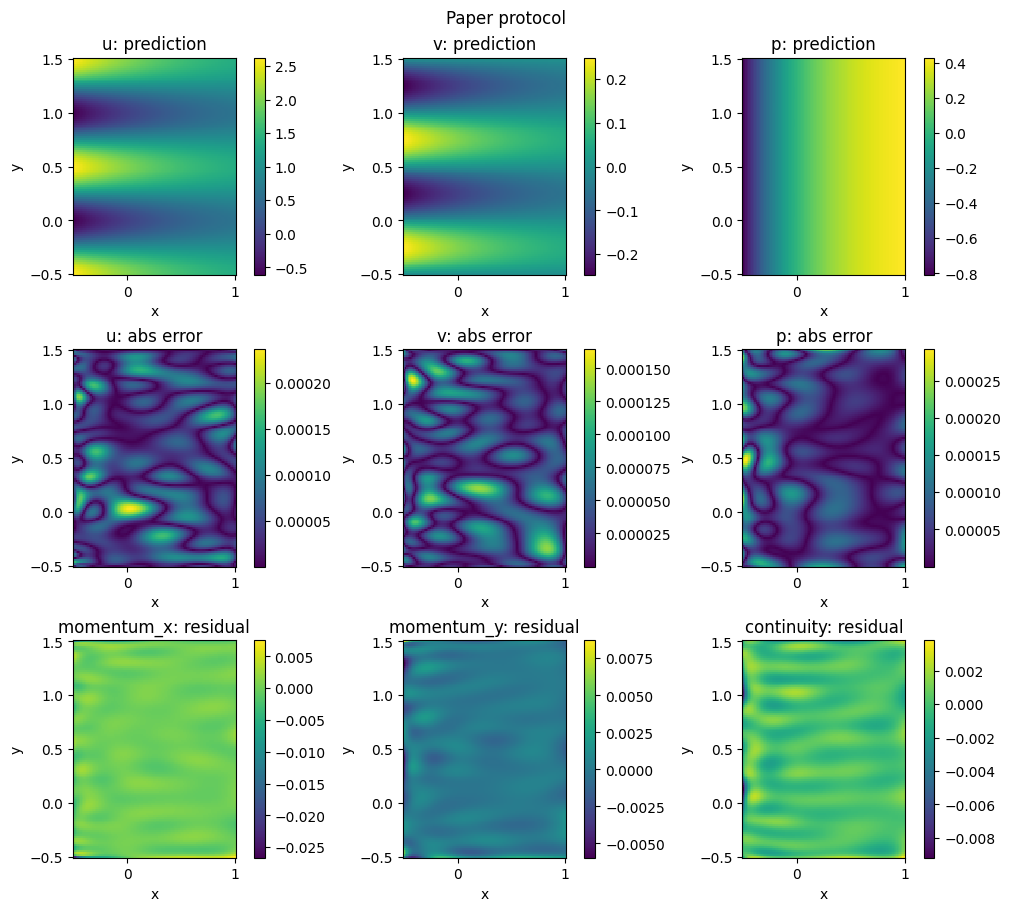

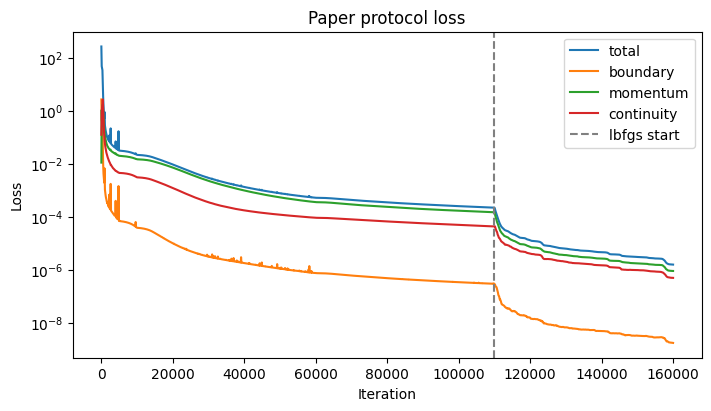

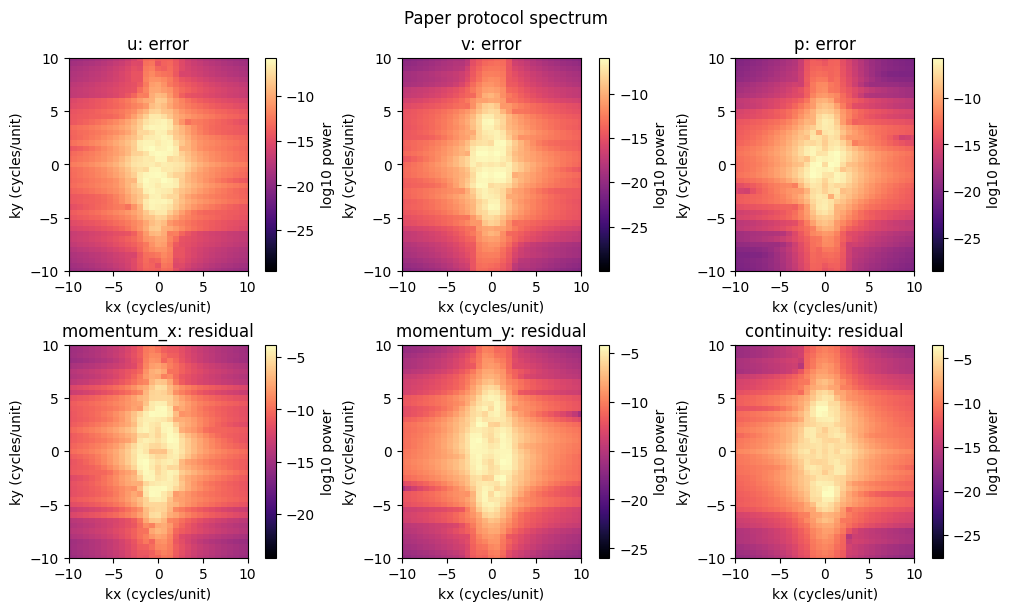

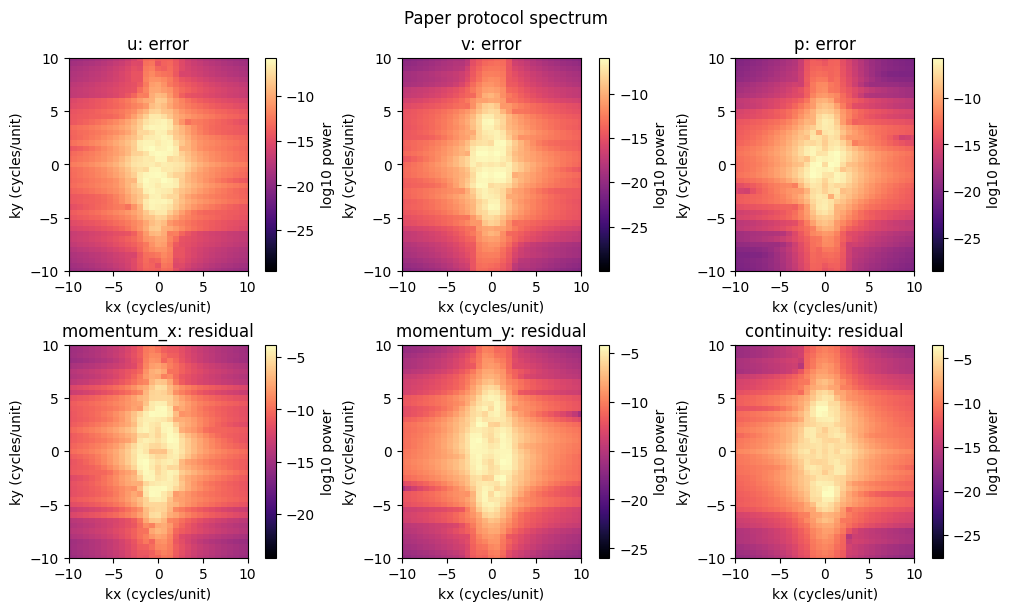

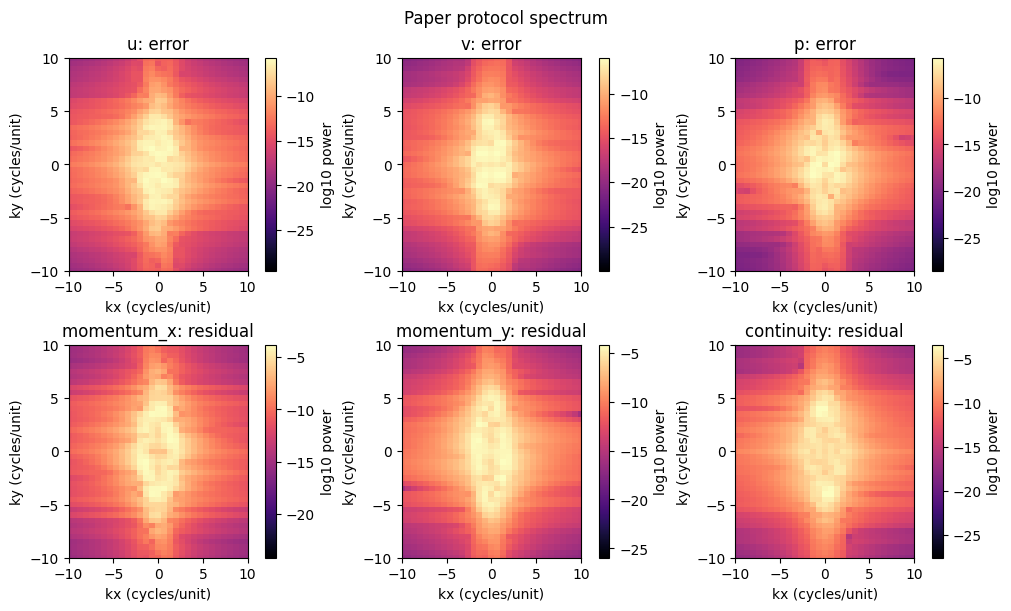

In [ ]:
import pandas as pd
from IPython.display import display

experiment_root = drive_root / 'results' / 'experiments'
experiment_root.mkdir(parents=True, exist_ok=True)
experiment_seed = 1234
validation_size = 81
report_size = 111
paper_layers, paper_width = 4, 50
paper_adam_steps = 110000
paper_lbfgs_maxiter = 50000
paper_lr = 1e-3
paper_decay_steps = (5000, 10000, 60000)
paper_decay_factors = (0.1, 0.1, 0.1)
experiment_weights = jnp.array([100.0, 1.0, 1.0])

experiment_keys = jax.random.split(jax.random.PRNGKey(experiment_seed), 10)
experiment_data = sample_data(experiment_keys[1], 2601, 100)


def summarize_experiment(name, result, phases, params, budget):
    metrics = result['metrics']
    errors = np.array([metrics[f'{field}_relative_l2'] for field in FIELDS])
    return dict(
        method=name, budget=int(budget),
        actual_updates=sum(int(p.get('updates', p.get('iterations', 0))) for p in phases),
        seconds=sum(float(p['seconds']) for p in phases),
        lbfgs_evaluations=sum(int(p.get('evaluations', 0)) for p in phases),
        parameters=sum(int(p.size) for p in jax.tree.leaves(params)),
        u_percent=100 * float(errors[0]), v_percent=100 * float(errors[1]),
        p_percent=100 * float(errors[2]),
        score=float(np.exp(np.mean(np.log(np.maximum(errors, 1e-16))))),
        residual_rms=float(np.sqrt(np.mean([metrics[f'{eq}_rms']**2 for eq in EQUATIONS]))),
        boundary_rms=metrics['boundary_velocity_rms'])


def save_experiment(folder, params, result, history, phases, summary, data, **settings):
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    (folder / 'summary.json').write_text(json.dumps(summary, indent=2))
    (folder / 'run.json').write_text(json.dumps(
        dict(settings=settings, metrics=result['metrics'], training=phases,
             seed=experiment_seed, loss_weights=experiment_weights.tolist(),
             versions={name: version(name) for name in ('jax', 'flax', 'optax')},
             devices=[str(device) for device in jax.devices()],
             timing='training including compilation; excludes evaluation and plotting'), indent=2))
    (folder / 'params.msgpack').write_bytes(serialization.to_bytes(params))
    write_csv(folder / 'loss.csv', history)
    np.savez_compressed(folder / 'training_data.npz',
                        interior=np.asarray(data[0]), boundary=np.asarray(data[1]),
                        boundary_uv=np.asarray(data[2]))
    # Full fields and spectra:
    # save_stage(folder / 'full', 1, params, result, history, phases, data, {}, **settings)


paper_model = MLP(paper_layers, paper_width, scl=1.0, act_s=0)
paper_initial_params = paper_model.init(experiment_keys[0], jnp.zeros(2))
paper_predict = sol_pred_create(paper_model)
paper_loss = loss_create(paper_predict, experiment_weights)

paper_params, paper_history, paper_adam_info = train_adam(
    paper_loss, paper_initial_params, experiment_data, paper_adam_steps, lr=paper_lr,
    lr_strategy='piecewise', decay_steps=paper_decay_steps,
    decay_factors=paper_decay_factors)
paper_adam_result = evaluate_stage(paper_predict, paper_params, experiment_data,
                                   report_size, report_size)
paper_adam_summary = summarize_experiment('Paper protocol: Adam', paper_adam_result,
                                          [paper_adam_info], paper_params, paper_adam_steps)
save_experiment(experiment_root / '01_paper/adam', paper_params, paper_adam_result,
                paper_history, [paper_adam_info], paper_adam_summary, experiment_data,
                layers=paper_layers, width=paper_width, kappa=1.0, activation=0, amplitude=1.0)

paper_params, paper_history, paper_lbfgs_info = train_lbfgs(
    paper_loss, paper_params, experiment_data,
    maxiter=paper_lbfgs_maxiter, history=paper_history)
paper_phases = [paper_adam_info, paper_lbfgs_info]
paper_result = evaluate_stage(paper_predict, paper_params, experiment_data,
                              report_size, report_size)
paper_summary = summarize_experiment('Paper protocol: our JAX run', paper_result,
                                     paper_phases, paper_params,
                                     paper_adam_steps + paper_lbfgs_maxiter)
save_experiment(experiment_root / '01_paper/final', paper_params, paper_result,
                paper_history, paper_phases, paper_summary, experiment_data,
                layers=paper_layers, width=paper_width, kappa=1.0, activation=0, amplitude=1.0)
display(pd.DataFrame([paper_adam_summary, paper_summary]))
paper_comparison(paper_result['metrics'], paper_layers, paper_width)
plot_fields(paper_result, 'Paper protocol')
plot_loss(paper_history, 'Paper protocol loss')
plot_spectrum(paper_result, 'Paper protocol spectrum')
plot_spectrum(paper_result, 'Paper protocol spectrum',
              kxlim=(-10, 10), kylim=(-10, 10))

## 2. Compare optimizers

adam  | Step      0 | Loss 2.729e+02 | BC 2.728e+00 | Momentum 1.126e-02 | Continuity 1.268e-01 | LR 1.000e-03
adam  | Step    100 | Loss 4.893e+01 | BC 4.695e-01 | Momentum 1.100e+00 | Continuity 8.779e-01 | LR 1.000e-03
adam  | Step    200 | Loss 4.165e+01 | BC 3.998e-01 | Momentum 2.666e-01 | Continuity 1.401e+00 | LR 1.000e-03
adam  | Step    300 | Loss 3.493e+01 | BC 3.239e-01 | Momentum 7.940e-01 | Continuity 1.751e+00 | LR 1.000e-03
adam  | Step    400 | Loss 1.014e+01 | BC 5.641e-02 | Momentum 1.781e+00 | Continuity 2.722e+00 | LR 1.000e-03
adam  | Step    500 | Loss 3.430e+00 | BC 1.021e-02 | Momentum 1.089e+00 | Continuity 1.319e+00 | LR 1.000e-03
adam  | Step    600 | Loss 1.519e+00 | BC 4.292e-03 | Momentum 6.001e-01 | Continuity 4.899e-01 | LR 1.000e-03
adam  | Step    700 | Loss 8.045e-01 | BC 2.742e-03 | Momentum 3.308e-01 | Continuity 1.995e-01 | LR 1.000e-03
adam  | Step    800 | Loss 5.287e-01 | BC 1.966e-03 | Momentum 2.182e-01 | Continuity 1.139e-01 | LR 1.000e-03
a

,method,budget,actual_updates,seconds,lbfgs_evaluations,parameters,u_percent,v_percent,p_percent,score,residual_rms,boundary_rms,time_target_seconds
0,SOAP(plateau),69734,69734,477.079083,0,7953,0.001952,0.017507,0.006555,0.000061,0.000385,0.000021,477.073448
1,Adam(plateau) + L-BFGS-B,160000,160000,479.075833,53922,7953,0.005268,0.047260,0.017226,0.000162,0.000816,0.000027,NaN
2,Adam(piecewise) + L-BFGS-B,160000,160000,477.073448,54293,7953,0.005327,0.047160,0.017833,0.000165,0.000861,0.000030,NaN


Lowest final error: SOAP(plateau)
SOAP updates: 69734
SOAP training time: 477.08 s
Adam runs share iteration caps; their training times can differ.
SOAP matches the original piecewise baseline’s total training time.
Timing includes compilation and loss logging, excluding evaluation and saving.
L-BFGS-B may stop early; SOAP may slightly exceed its time budget.


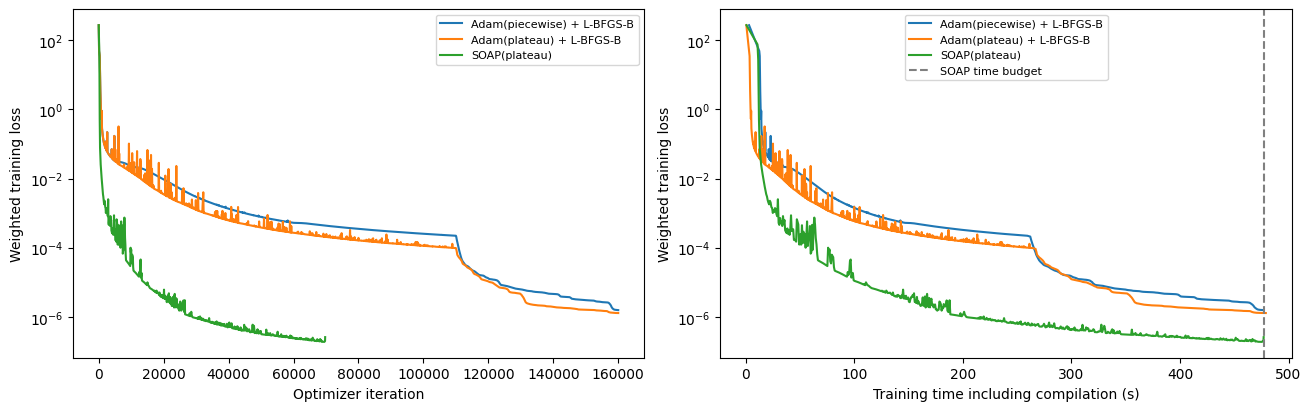

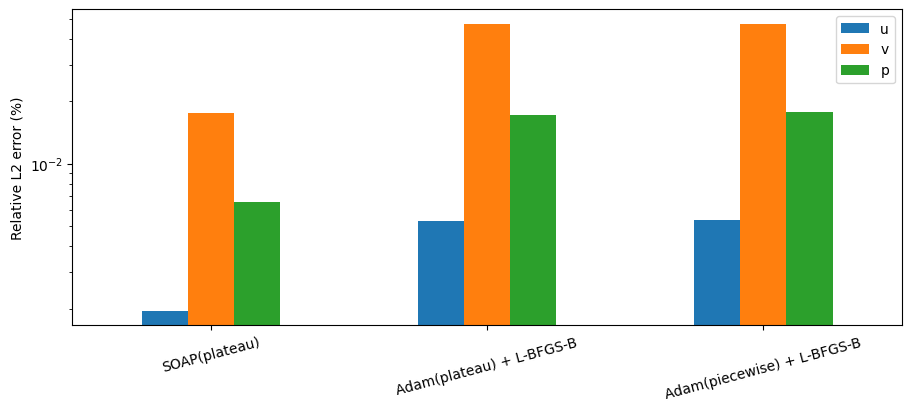

In [ ]:
## 2. Compare training methods

optimizer_lr = 1e-3
optimizer_lr_min = 1e-6

optimizer_folder = experiment_root / '03_optimizer'
optimizer_folder.mkdir(parents=True, exist_ok=True)

# Original Adam(piecewise) + L-BFGS-B from section 1.
baseline_folder = experiment_root / '01_paper/final'
baseline_summary = json.loads(
    (baseline_folder / 'summary.json').read_text())
baseline_run = json.loads(
    (baseline_folder / 'run.json').read_text())
baseline_history = pd.read_csv(
    baseline_folder / 'loss.csv').to_dict('records')

soap_time_limit = sum(
    float(p['seconds']) for p in baseline_run['training'])

baseline_row = dict(baseline_summary)
baseline_row['method'] = 'Adam(piecewise) + L-BFGS-B'

optimizer_rows = [baseline_row]
optimizer_histories = {
    'Adam(piecewise) + L-BFGS-B': baseline_history
}


# Adam(plateau), followed by L-BFGS-B.
plateau_params, plateau_history, plateau_adam_info = train_adam(
    paper_loss,
    paper_initial_params,
    experiment_data,
    paper_adam_steps,
    lr=optimizer_lr,
    lr_strategy='plateau',
    lr_min=optimizer_lr_min,
    plateau_factor=0.5,
    plateau_patience=10,
    plateau_window=100,
    time_limit=None)

plateau_params, plateau_history, plateau_lbfgs_info = train_lbfgs(
    paper_loss,
    plateau_params,
    experiment_data,
    maxiter=paper_lbfgs_maxiter,
    history=plateau_history)

plateau_phases = [plateau_adam_info, plateau_lbfgs_info]

plateau_result = evaluate_stage(
    paper_predict, plateau_params, experiment_data,
    report_size, report_size)

plateau_summary = summarize_experiment(
    'Adam(plateau) + L-BFGS-B',
    plateau_result,
    plateau_phases,
    plateau_params,
    paper_adam_steps + paper_lbfgs_maxiter)

save_experiment(
    optimizer_folder / 'adam_plateau_lbfgs',
    plateau_params,
    plateau_result,
    plateau_history,
    plateau_phases,
    plateau_summary,
    experiment_data,
    layers=paper_layers,
    width=paper_width,
    kappa=1.0,
    activation=0,
    amplitude=1.0,
    evaluation='report',
    evaluation_size=report_size,
    lr_strategy='plateau',
    lr=optimizer_lr,
    lr_min=optimizer_lr_min,
    adam_updates=paper_adam_steps,
    lbfgs_maxiter=paper_lbfgs_maxiter)

optimizer_rows.append(plateau_summary)
optimizer_histories['Adam(plateau) + L-BFGS-B'] = plateau_history


# SOAP(plateau), using the original baseline's total time.
print(f'Original baseline time / SOAP budget: {soap_time_limit:.2f} s')
print(f"Adam(plateau) + L-BFGS-B time: {plateau_summary['seconds']:.2f} s")

soap_params, soap_history, soap_info = train_soap(
    paper_loss,
    paper_initial_params,
    experiment_data,
    paper_adam_steps,
    lr=optimizer_lr,
    lr_strategy='plateau',
    lr_min=optimizer_lr_min,
    plateau_factor=0.5,
    plateau_patience=10,
    plateau_window=100,
    time_limit=soap_time_limit)

soap_result = evaluate_stage(
    paper_predict, soap_params, experiment_data,
    report_size, report_size)

soap_summary = summarize_experiment(
    'SOAP(plateau)',
    soap_result,
    [soap_info],
    soap_params,
    int(soap_info['updates']))
soap_summary['time_target_seconds'] = soap_time_limit

save_experiment(
    optimizer_folder / 'soap',
    soap_params,
    soap_result,
    soap_history,
    [soap_info],
    soap_summary,
    experiment_data,
    layers=paper_layers,
    width=paper_width,
    kappa=1.0,
    activation=0,
    amplitude=1.0,
    evaluation='report',
    evaluation_size=report_size,
    lr_strategy='plateau',
    lr=optimizer_lr,
    lr_min=optimizer_lr_min,
    time_target_seconds=soap_time_limit)

optimizer_rows.append(soap_summary)
optimizer_histories['SOAP(plateau)'] = soap_history


# Compare final results.
optimizer_table = (
    pd.DataFrame(optimizer_rows)
    .sort_values('score')
    .reset_index(drop=True)
)
optimizer_table.to_csv(
    optimizer_folder / 'summary.csv', index=False)

best_method = str(optimizer_table.iloc[0]['method'])
best_optimizer = {
    'Adam(piecewise) + L-BFGS-B': 'adam_lbfgs',
    'Adam(plateau) + L-BFGS-B': 'adam_lbfgs',
    'SOAP(plateau)': 'soap',
}[best_method]
best_optimizer_strategy = (
    'piecewise' if best_method == 'Adam(piecewise) + L-BFGS-B'
    else 'plateau'
)

display(optimizer_table)
print('Lowest final error:', best_method)
print('SOAP updates:', soap_info['updates'])
print(f"SOAP training time: {soap_info['seconds']:.2f} s")
print('Adam runs share iteration caps; their training times can differ.')
print('SOAP matches the original piecewise baseline’s total training time.')
print('Timing includes compilation and loss logging, excluding evaluation and saving.')
print('L-BFGS-B may stop early; SOAP may slightly exceed its time budget.')


# Loss curves.
fig, axes = plt.subplots(
    1, 2, figsize=(13, 4), constrained_layout=True)

for name, history in optimizer_histories.items():
    losses = [r['total'] for r in history]
    axes[0].semilogy(
        [r['iteration'] for r in history], losses, label=name)
    axes[1].semilogy(
        [r['seconds'] for r in history], losses, label=name)

axes[0].set(
    xlabel='Optimizer iteration',
    ylabel='Weighted training loss')
axes[1].set(
    xlabel='Training time including compilation (s)',
    ylabel='Weighted training loss')
axes[1].axvline(
    soap_time_limit, color='gray', linestyle='--',
    label='SOAP time budget')

for ax in axes:
    ax.legend(fontsize=8)

fig.savefig(optimizer_folder / 'comparison.png', dpi=180)
plt.show()


# Final solution errors.
fig, ax = plt.subplots(
    figsize=(9, 4), constrained_layout=True)

optimizer_table.set_index('method')[
    ['u_percent', 'v_percent', 'p_percent']
].plot.bar(ax=ax, rot=15)

ax.set(
    yscale='log',
    xlabel='',
    ylabel='Relative L2 error (%)')
ax.legend(['u', 'v', 'p'])

fig.savefig(optimizer_folder / 'final_errors.png', dpi=180)
plt.show()

## 3. Compare learning-rate strategies

soap  | Step      0 | Loss 2.729e+02 | BC 2.728e+00 | Momentum 1.126e-02 | Continuity 1.268e-01 | LR 1.000e-03
soap  | Step    100 | Loss 7.579e+01 | BC 7.573e-01 | Momentum 2.365e-02 | Continuity 3.429e-02 | LR 1.000e-03
soap  | Step    200 | Loss 2.717e+01 | BC 2.603e-01 | Momentum 5.957e-01 | Continuity 5.415e-01 | LR 1.000e-03
soap  | Step    300 | Loss 5.193e-01 | BC 2.295e-03 | Momentum 1.918e-01 | Continuity 9.795e-02 | LR 1.000e-03
soap  | Step    400 | Loss 7.771e-02 | BC 2.551e-04 | Momentum 3.860e-02 | Continuity 1.359e-02 | LR 1.000e-03
soap  | Step    500 | Loss 4.292e-02 | BC 1.576e-04 | Momentum 2.087e-02 | Continuity 6.290e-03 | LR 1.000e-03
soap  | Step    600 | Loss 2.553e-02 | BC 7.470e-05 | Momentum 1.412e-02 | Continuity 3.938e-03 | LR 1.000e-03
soap  | Step    700 | Loss 1.818e-02 | BC 4.673e-05 | Momentum 1.070e-02 | Continuity 2.809e-03 | LR 1.000e-03
soap  | Step    800 | Loss 1.341e-02 | BC 3.066e-05 | Momentum 8.200e-03 | Continuity 2.141e-03 | LR 1.000e-03
s

,method,budget,actual_updates,seconds,lbfgs_evaluations,parameters,u_percent,v_percent,p_percent,score,residual_rms,boundary_rms
0,cosine,20000,20000,138.426107,0,7953,0.007928,0.065662,0.026806,0.000241,0.001469,0.000050
1,plateau,20000,20000,139.532393,0,7953,0.006918,0.077246,0.031648,0.000257,0.001339,0.000063
2,piecewise,20000,20000,137.742509,0,7953,0.014625,0.146855,0.058704,0.000501,0.002706,0.000090
3,constant,20000,20000,137.021056,0,7953,0.038669,0.194915,0.053854,0.000740,0.001488,0.000342


Optimizer: SOAP | Updates per strategy: 20000
Suggested strategy: cosine
Selection: geometric mean of validation relative L2 errors in u, v, p.
Piecewise drops at 5,000 and 10,000; its 60,000-step drop is not reached.


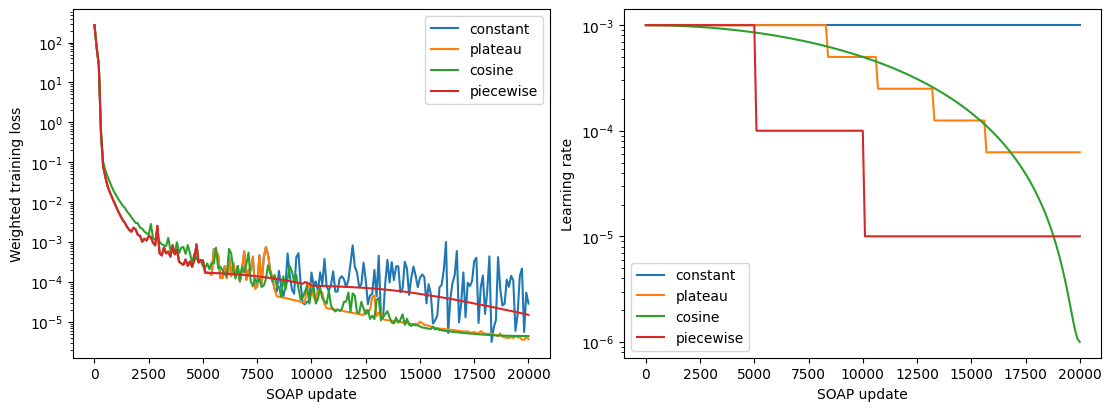

In [ ]:
lr_budget = 20000
lr_start = 1e-3
lr_floor = 1e-6
lr_strategies = ('constant', 'plateau', 'cosine', 'piecewise')

lr_folder = experiment_root / '02_learning_rate_soap'
lr_folder.mkdir(parents=True, exist_ok=True)
lr_rows, lr_histories = [], {}

for strategy in lr_strategies:
    params, history, info = train_soap(
        paper_loss, paper_initial_params, experiment_data,
        lr_budget,
        lr=lr_start,
        lr_strategy=strategy,
        lr_min=lr_floor,
        decay_steps=paper_decay_steps,
        decay_factors=paper_decay_factors,
        plateau_factor=0.5,
        plateau_patience=10,
        plateau_window=100,
        time_limit=None)

    result = evaluate_stage(
        paper_predict, params, experiment_data,
        validation_size, validation_size)

    row = summarize_experiment(
        strategy, result, [info], params, lr_budget)
    lr_rows.append(row)
    lr_histories[strategy] = history

    save_experiment(
        lr_folder / strategy,
        params, result, history, [info], row, experiment_data,
        layers=paper_layers,
        width=paper_width,
        kappa=1.0,
        activation=0,
        amplitude=1.0,
        evaluation='validation',
        evaluation_size=validation_size,
        optimizer='soap',
        lr_strategy=strategy,
        lr=lr_start,
        lr_min=lr_floor,
        updates=lr_budget,
        decay_steps=paper_decay_steps,
        decay_factors=paper_decay_factors,
        plateau_factor=0.5,
        plateau_patience=10,
        plateau_window=100)

lr_table = (
    pd.DataFrame(lr_rows)
    .sort_values('score')
    .reset_index(drop=True)
)
best_lr_strategy = str(lr_table.loc[0, 'method'])

lr_table.to_csv(lr_folder / 'summary.csv', index=False)
display(lr_table)

print('Optimizer: SOAP | Updates per strategy:', lr_budget)
print('Suggested strategy:', best_lr_strategy)
print('Selection: geometric mean of validation relative L2 errors in u, v, p.')
print('Piecewise drops at 5,000 and 10,000; its 60,000-step drop is not reached.')

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)

for name, history in lr_histories.items():
    steps = [r['iteration'] for r in history]
    axes[0].semilogy(
        steps, [r['total'] for r in history], label=name)
    axes[1].semilogy(
        steps, [r['learning_rate'] for r in history], label=name)

axes[0].set(xlabel='SOAP update', ylabel='Weighted training loss')
axes[1].set(xlabel='SOAP update', ylabel='Learning rate')

for ax in axes:
    ax.legend()

fig.savefig(lr_folder / 'comparison.png', dpi=180)
plt.show()

## 4. Updated single-stage benchmark

soap  | Step      0 | Loss 2.729e+02 | BC 2.728e+00 | Momentum 1.126e-02 | Continuity 1.268e-01 | LR 1.000e-03
soap  | Step    100 | Loss 7.579e+01 | BC 7.573e-01 | Momentum 2.365e-02 | Continuity 3.429e-02 | LR 1.000e-03
soap  | Step    200 | Loss 2.717e+01 | BC 2.603e-01 | Momentum 5.957e-01 | Continuity 5.415e-01 | LR 1.000e-03
soap  | Step    300 | Loss 5.193e-01 | BC 2.295e-03 | Momentum 1.918e-01 | Continuity 9.795e-02 | LR 1.000e-03
soap  | Step    400 | Loss 7.771e-02 | BC 2.551e-04 | Momentum 3.860e-02 | Continuity 1.359e-02 | LR 1.000e-03
soap  | Step    500 | Loss 4.292e-02 | BC 1.576e-04 | Momentum 2.087e-02 | Continuity 6.290e-03 | LR 1.000e-03
soap  | Step    600 | Loss 2.553e-02 | BC 7.470e-05 | Momentum 1.412e-02 | Continuity 3.938e-03 | LR 1.000e-03
soap  | Step    700 | Loss 1.818e-02 | BC 4.673e-05 | Momentum 1.070e-02 | Continuity 2.809e-03 | LR 1.000e-03
soap  | Step    800 | Loss 1.341e-02 | BC 3.066e-05 | Momentum 8.200e-03 | Continuity 2.141e-03 | LR 1.000e-03
s

,method,budget,actual_updates,seconds,lbfgs_evaluations,parameters,u_percent,v_percent,p_percent,score,residual_rms,boundary_rms
0,Updated single stage,44882,44882,307.054681,0,7953,0.00283,0.022053,0.009477,0.000084,0.000515,0.000019



Stage 1: 4 x 50; relative L2 error (%)
Field             Ours         Paper
u             0.002830      0.076000
v             0.022053      0.412000
p             0.009477      0.516000
Paper: Table 1, VP, alpha=100; each entry is best of ten runs.
Ours: one seed; current training budget; independent evaluation grid.
Same initialization, training points and loss weights as cell 1.
SOAP: exactly 44,882 updates with plateau LR; no L-BFGS-B.


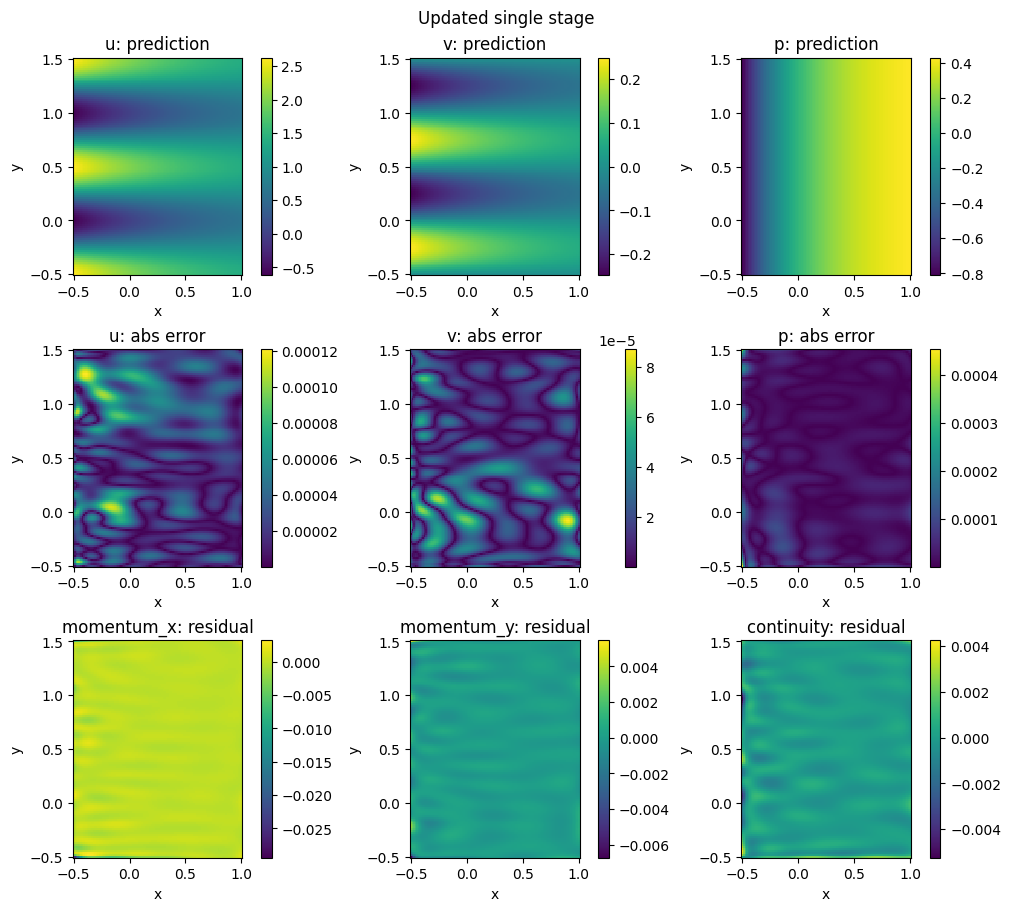

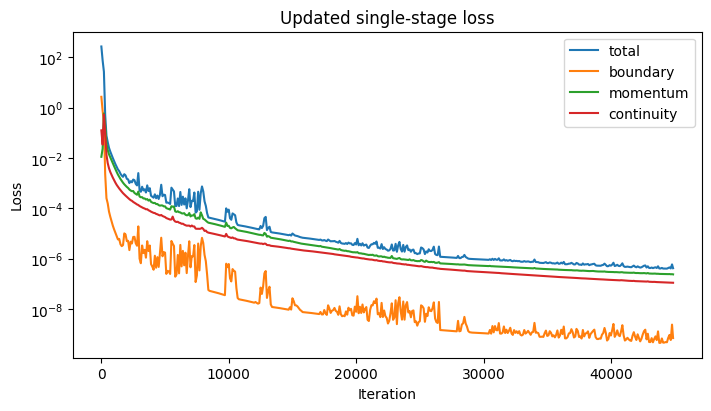

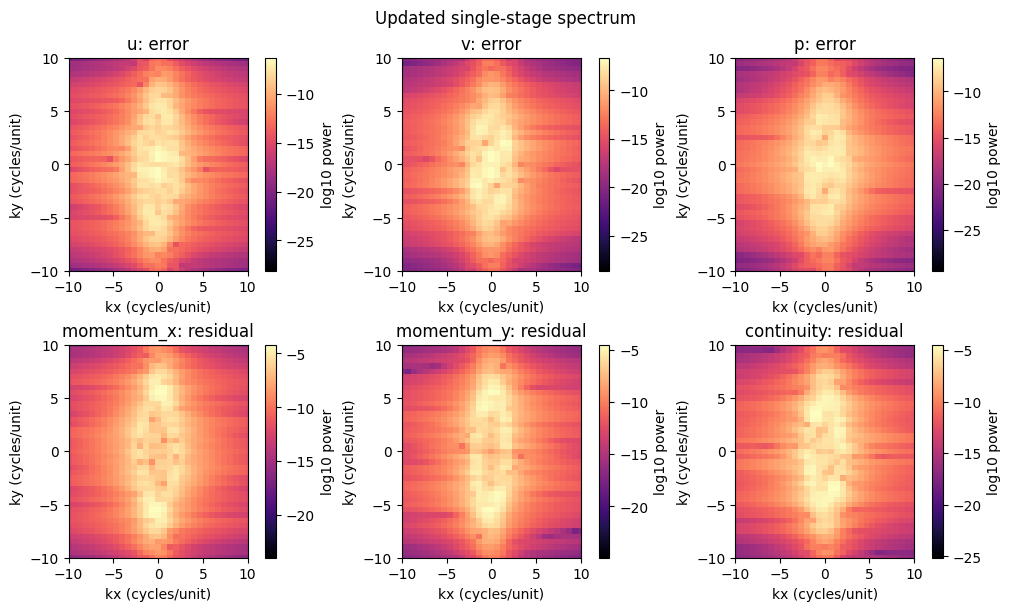

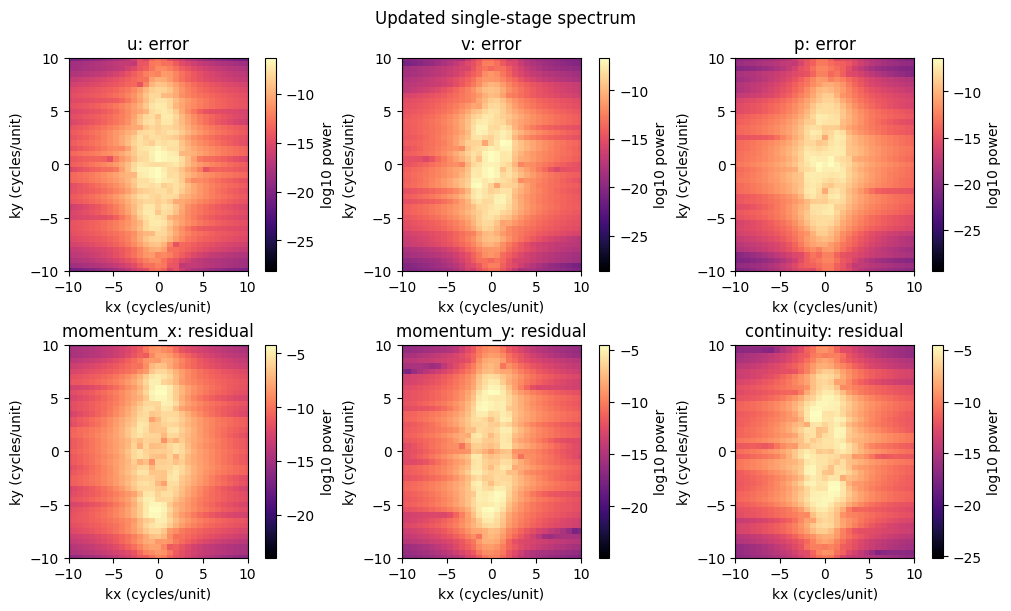

In [ ]:
selected_optimizer = 'soap'
selected_lr_strategy = 'plateau'
updated_epoch = 44882
updated_lr = 1e-3
updated_lr_min = 1e-6
updated_lbfgs_maxiter = paper_lbfgs_maxiter

updated_model = MLP(paper_layers, paper_width, scl=1.0, act_s=0)
updated_initial_params = updated_model.init(experiment_keys[0], jnp.zeros(2))
updated_predict = sol_pred_create(updated_model)
updated_data = experiment_data
updated_loss = loss_create(updated_predict, experiment_weights)
updated_phases, updated_history = [], []
trainer = {'adam': train_adam, 'soap': train_soap,
           'adam_lbfgs': train_adam}[selected_optimizer]
updated_params, updated_history, info = trainer(
    updated_loss, updated_initial_params, updated_data, updated_epoch, lr=updated_lr,
    lr_strategy=selected_lr_strategy, lr_min=updated_lr_min,
    decay_steps=paper_decay_steps, decay_factors=paper_decay_factors,
    plateau_factor=0.5, plateau_patience=10, plateau_window=100,
    time_limit=None, history=updated_history)
updated_phases.append(info)
updated_budget = updated_epoch
if selected_optimizer == 'adam_lbfgs':
    updated_params, updated_history, info = train_lbfgs(
        updated_loss, updated_params, updated_data,
        maxiter=updated_lbfgs_maxiter, history=updated_history)
    updated_phases.append(info)
    updated_budget += updated_lbfgs_maxiter

updated_result = evaluate_stage(updated_predict, updated_params, updated_data,
                                report_size, report_size)
updated_summary = summarize_experiment('Updated single stage', updated_result,
                                       updated_phases, updated_params, updated_budget)
save_experiment(experiment_root / '04_updated/final', updated_params, updated_result,
                updated_history, updated_phases, updated_summary, updated_data,
                layers=paper_layers, width=paper_width, kappa=1.0, activation=0, amplitude=1.0,
                selected_optimizer=selected_optimizer, selected_strategy=selected_lr_strategy)
display(pd.DataFrame([updated_summary]))
paper_comparison(updated_result['metrics'], paper_layers, paper_width)
print('Same initialization, training points and loss weights as cell 1.')
print('SOAP: exactly 44,882 updates with plateau LR; no L-BFGS-B.')
plot_fields(updated_result, 'Updated single stage')
plot_loss(updated_history, 'Updated single-stage loss')
plot_spectrum(updated_result, 'Updated single-stage spectrum')

## 5. Multistage training

In [ ]:
rootdir = experiment_root / '05_multistage'
nx = ny = report_size

updated_saved = json.loads(
    (experiment_root / '04_updated/final/summary.json').read_text())

reference_seconds = float(updated_saved['seconds'])
stage_time_factors = (0.5, 0.5)
stage_time_limits = [
    factor * reference_seconds for factor in stage_time_factors
]

print(f'T = updated single-stage training time: {reference_seconds:.2f} s')
for i, seconds in enumerate(stage_time_limits, 1):
    print(f'Stage {i}: {stage_time_factors[i - 1]}T = {seconds:.2f} s')
print(f'Total target: {sum(stage_time_factors):.1f}T')

T = updated single-stage training time: 307.05 s
Stage 1: 0.5T = 153.53 s
Stage 2: 0.5T = 153.53 s
Total target: 1.0T


### Stage 1

In [ ]:
n_hl1 = 4
n_unit1 = 50
scl1 = 1.0  # kappa
act_s_stage1 = 0  # 0: tanh; 1: sine in the first layer
epsil1 = 1.0
N_col1 = 2601
N_bd1 = 100  # intervals per edge; 400 unique boundary points
lw1 = jnp.array([100.0, 1.0, 1.0])  # boundary, momentum, continuity

model1 = MLP(n_hl1, n_unit1, scl=scl1, act_s=act_s_stage1)
trained_params1 = model1.init(keys[0], jnp.zeros(2))
pred_u1 = sol_pred_create(model1, epsil1)
data1 = sample_data(keys[1], N_col1, N_bd1)
NN_loss1 = loss_create(pred_u1, lw1)
loss11, training1 = [], []

In [ ]:
lr_soap1 = 1e-3
lr_strategy_soap1 = 'plateau'
lr_min_soap1 = 1e-6
epoch_soap1 = 44882  # Schedule argument; time_limit controls stopping.

trained_params1, loss11, info1 = train_soap(
    NN_loss1, trained_params1, data1, epoch_soap1,
    lr=lr_soap1,
    lr_strategy=lr_strategy_soap1,
    lr_min=lr_min_soap1,
    plateau_factor=0.5,
    plateau_patience=10,
    plateau_window=100,
    time_limit=stage_time_limits[0],
    history=loss11)
training1.append(info1)

soap  | Step      0 | Loss 2.729e+02 | BC 2.728e+00 | Momentum 1.126e-02 | Continuity 1.268e-01 | LR 1.000e-03
soap  | Step    100 | Loss 7.579e+01 | BC 7.573e-01 | Momentum 2.365e-02 | Continuity 3.429e-02 | LR 1.000e-03
soap  | Step    200 | Loss 2.717e+01 | BC 2.603e-01 | Momentum 5.957e-01 | Continuity 5.415e-01 | LR 1.000e-03
soap  | Step    300 | Loss 5.193e-01 | BC 2.295e-03 | Momentum 1.918e-01 | Continuity 9.795e-02 | LR 1.000e-03
soap  | Step    400 | Loss 7.771e-02 | BC 2.551e-04 | Momentum 3.860e-02 | Continuity 1.359e-02 | LR 1.000e-03
soap  | Step    500 | Loss 4.292e-02 | BC 1.576e-04 | Momentum 2.087e-02 | Continuity 6.290e-03 | LR 1.000e-03
soap  | Step    600 | Loss 2.553e-02 | BC 7.470e-05 | Momentum 1.412e-02 | Continuity 3.938e-03 | LR 1.000e-03
soap  | Step    700 | Loss 1.818e-02 | BC 4.673e-05 | Momentum 1.070e-02 | Continuity 2.809e-03 | LR 1.000e-03
soap  | Step    800 | Loss 1.341e-02 | BC 3.066e-05 | Momentum 8.200e-03 | Continuity 2.141e-03 | LR 1.000e-03
s

### Results of Stage 1


Stage 1: 4 x 50; relative L2 error (%)
Field             Ours         Paper
u             0.008355      0.076000
v             0.094799      0.412000
p             0.032022      0.516000
Paper: Table 1, VP, alpha=100; each entry is best of ten runs.
Ours: one seed; current training budget; independent evaluation grid.
{
  "pressure_shift": -0.6419337285461992,
  "u_relative_l2": 8.355272048348317e-05,
  "u_rmse": 0.00010060784704946725,
  "v_relative_l2": 0.0009479851059015904,
  "v_rmse": 9.498318766193601e-05,
  "p_relative_l2": 0.0003202245944661268,
  "p_rmse": 0.00011128626351339007,
  "momentum_x_rms": 0.0013329195355040277,
  "momentum_y_rms": 0.0007689905464867231,
  "continuity_rms": 0.0010568079862254092,
  "boundary_velocity_rms": 0.00010363733466503003
}
Training: [{'optimizer': 'soap', 'updates': 22119, 'seconds': 153.53403185699972, 'time_limit': 153.527340612, 'schedule_steps': 44882, 'loss_normalization': 1.0, 'lr': 0.001, 'lr_strategy': 'plateau', 'lr_min': 1e-06, 'lr

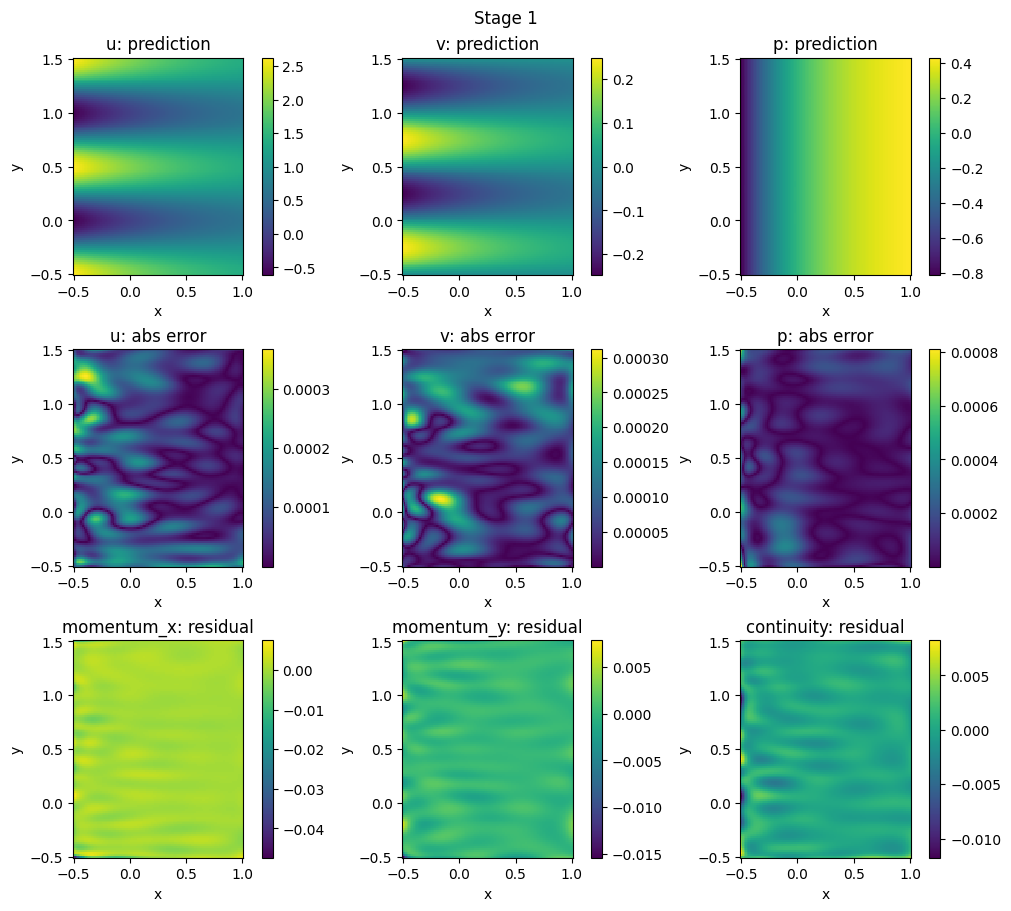

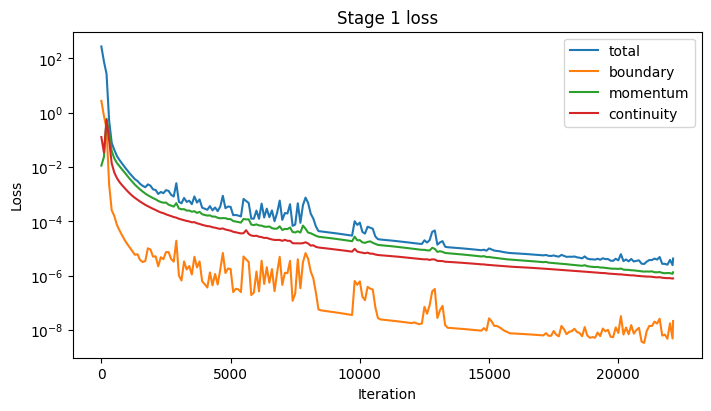

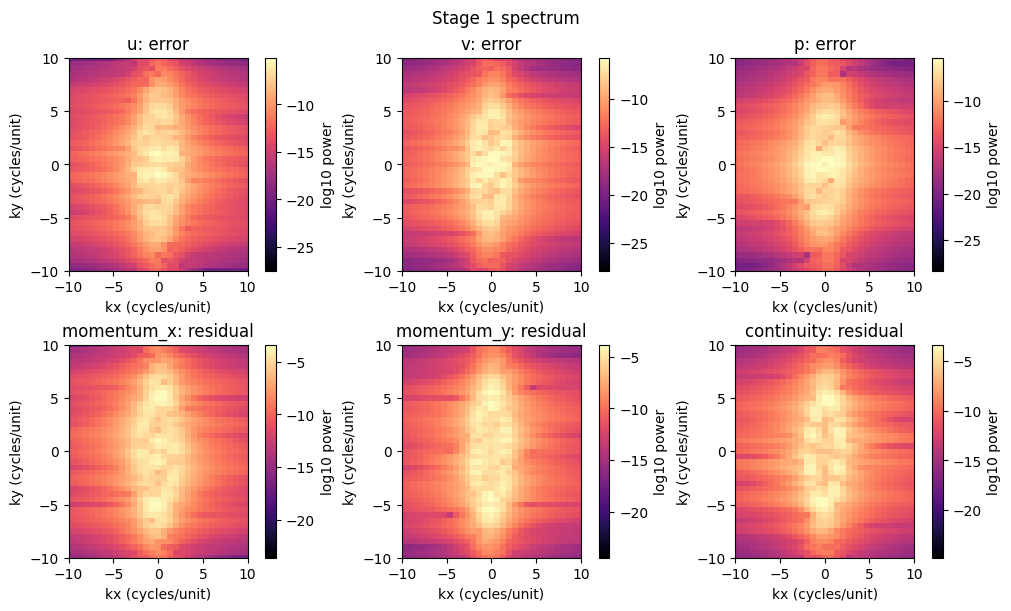

In [ ]:
result1 = evaluate_stage(pred_u1, trained_params1, data1, nx, ny)
comparison1 = paper_comparison(result1['metrics'], n_hl1, n_unit1)
print(json.dumps(result1['metrics'], indent=2))
print('Training:', training1)
figures1 = dict(fields=plot_fields(result1, 'Stage 1'),
                loss=plot_loss(loss11, 'Stage 1 loss'),
                spectrum=plot_spectrum(result1, 'Stage 1 spectrum'))

In [ ]:
save_stage(rootdir, 1, trained_params1, result1, loss11, training1, data1,
           figures1, comparison1, seed=seed, n_hl=n_hl1, n_unit=n_unit1,
           scl=scl1, act_s=act_s_stage1, epsil=epsil1, lw=lw1.tolist())

### Stage 2

In [ ]:
n_hl2 = 4
n_unit2 = 50
scl2 = 2*np.pi*5  # kappa
act_s_stage2 = 1
epsil2 = 7e-5
N_col2 = 2601*2
N_bd2 = 100*2
lw2 = jnp.array([100.0, 1.0, 1.0])

model2 = MLP(n_hl2, n_unit2, zero_output=True, scl=scl2, act_s=act_s_stage2)
trained_params2 = model2.init(keys[5], jnp.zeros(2))
# Capture baseline parameters while keeping their spatial derivatives.
f_u1 = lambda z, p=trained_params1: pred_u1(p, z)
pred_u2 = sol_pred_create(model2, epsil2, previous=f_u1)
data2 = sample_data(keys[6], N_col2, N_bd2)
NN_loss2 = loss_create(pred_u2, lw2)
loss21, training2 = [], []

In [ ]:
lr_soap2 = 1e-3
lr_strategy_soap2 = 'plateau'
lr_min_soap2 = 1e-6
epoch_soap2 = 44882

trained_params2, loss21, info2 = train_soap(
    NN_loss2, trained_params2, data2, epoch_soap2,
    lr=lr_soap2,
    lr_strategy=lr_strategy_soap2,
    lr_min=lr_min_soap2,
    plateau_factor=0.5,
    plateau_patience=10,
    plateau_window=100,
    normalize=True,
    time_limit=stage_time_limits[1],
    history=loss21)
training2.append(info2)

soap  | Step      0 | Loss 5.005e-06 | BC 2.148e-08 | Momentum 1.938e-06 | Continuity 9.198e-07 | LR 1.000e-03
soap  | Step    100 | Loss 3.637e-06 | BC 1.221e-08 | Momentum 1.580e-06 | Continuity 8.351e-07 | LR 1.000e-03
soap  | Step    200 | Loss 1.445e-06 | BC 3.494e-09 | Momentum 6.464e-07 | Continuity 4.490e-07 | LR 1.000e-03
soap  | Step    300 | Loss 4.174e-07 | BC 8.851e-10 | Momentum 2.109e-07 | Continuity 1.180e-07 | LR 1.000e-03
soap  | Step    400 | Loss 1.352e-07 | BC 2.559e-10 | Momentum 7.417e-08 | Continuity 3.542e-08 | LR 1.000e-03
soap  | Step    500 | Loss 6.307e-08 | BC 9.889e-11 | Momentum 3.518e-08 | Continuity 1.801e-08 | LR 1.000e-03
soap  | Step    600 | Loss 3.697e-08 | BC 4.899e-11 | Momentum 2.077e-08 | Continuity 1.130e-08 | LR 1.000e-03
soap  | Step    700 | Loss 2.474e-08 | BC 2.988e-11 | Momentum 1.392e-08 | Continuity 7.835e-09 | LR 1.000e-03
soap  | Step    800 | Loss 1.796e-08 | BC 1.985e-11 | Momentum 1.019e-08 | Continuity 5.790e-09 | LR 1.000e-03
s

### Results of Stage 2

{
  "pressure_shift": -0.641918611883892,
  "u_relative_l2": 2.1008634605588496e-06,
  "u_rmse": 2.529700391425338e-06,
  "v_relative_l2": 1.2503200764067379e-05,
  "v_rmse": 1.2527558261780924e-06,
  "p_relative_l2": 2.0596996962842638e-05,
  "p_rmse": 7.157984961813621e-06,
  "momentum_x_rms": 0.0004762377693445266,
  "momentum_y_rms": 0.0002126585028903928,
  "continuity_rms": 9.400746700511715e-05,
  "boundary_velocity_rms": 2.3309754250655037e-07
}
Training: [{'optimizer': 'soap', 'updates': 17821, 'seconds': 153.53237033100004, 'time_limit': 153.527340612, 'schedule_steps': 44882, 'loss_normalization': 5.0054987470396365e-06, 'lr': 0.001, 'lr_strategy': 'plateau', 'lr_min': 1e-06, 'lr_decay_steps': 5000, 'lr_decay_rate': 0.9, 'decay_steps': (), 'decay_factors': (), 'plateau_factor': 0.5, 'plateau_patience': 10, 'plateau_window': 100, 'plateau_rtol': 0.001, 'plateau_metric': 'unscaled weighted training loss before each update'}]


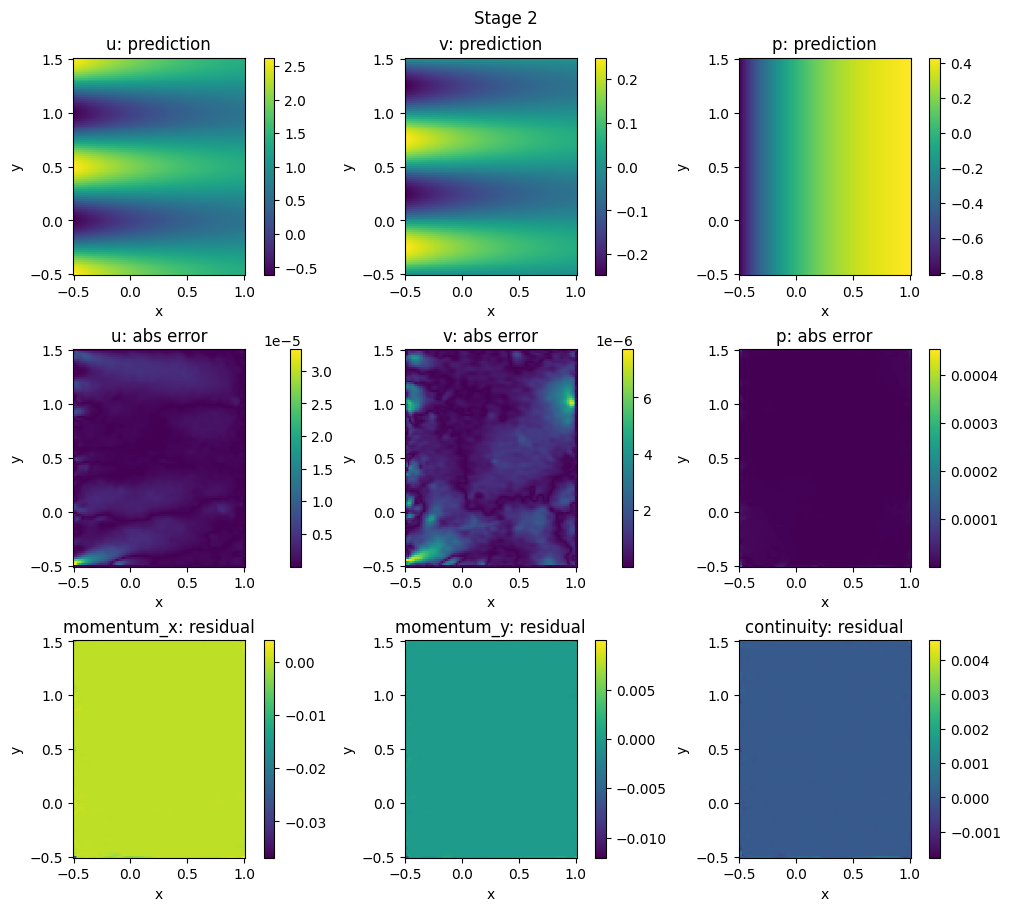

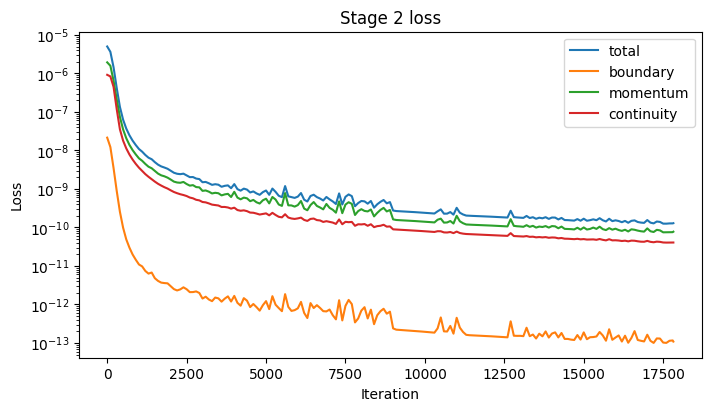

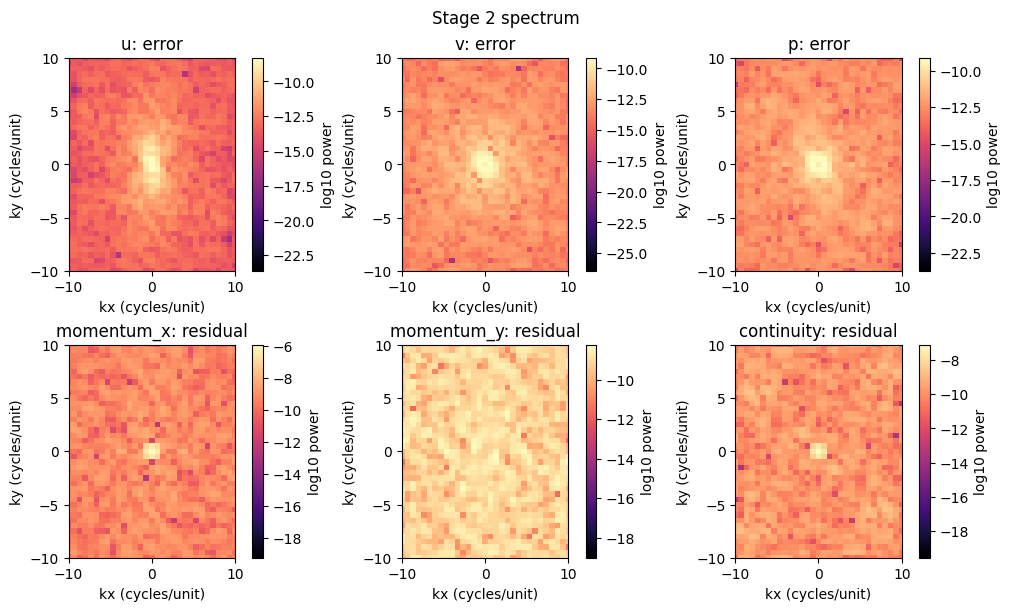

In [ ]:
result2 = evaluate_stage(pred_u2, trained_params2, data2, nx, ny)
print(json.dumps(result2['metrics'], indent=2))
print('Training:', training2)
figures2 = dict(fields=plot_fields(result2, 'Stage 2'),
                loss=plot_loss(loss21, 'Stage 2 loss'),
                spectrum=plot_spectrum(result2, 'Stage 2 spectrum'))

In [ ]:
save_stage(rootdir, 2, trained_params2, result2, loss21, training2, data2,
           figures2, seed=seed, n_hl=n_hl2, n_unit=n_unit2,
           scl=scl2, act_s=act_s_stage2, epsil=epsil2, lw=lw2.tolist())

## 6. Final comparison

,method,budget,actual_updates,seconds,lbfgs_evaluations,parameters,u_percent,v_percent,p_percent,score,residual_rms,boundary_rms,time_over_T,error_reduction_vs_updated
0,Original 1: Adam + L-BFGS-B,160000,160000,477.073448,54293,7953,0.005327,0.047160,0.017833,0.000165,0.000861,2.956334e-05,1.553708,0.509156
1,Updated 4: SOAP,44882,44882,307.054681,0,7953,0.002830,0.022053,0.009477,0.000084,0.000515,1.875036e-05,1.000000,1.000000
2,Multistage 5: two-stage SOAP,39940,39940,307.066402,0,15906,0.000210,0.001250,0.002060,0.000008,0.000306,2.330975e-07,1.000038,10.301153


Compared: paper-reference, updated single-stage, and two-stage PINN.
Multistage time and parameter counts include both stages.
Actual updates: paper = 160000; updated = 44882; multistage = 22119 + 17821 = 39940.
Compare actual iterations and training time; iteration costs differ.


,method,u_percent,v_percent,p_percent
0,Paper: reported best-of-ten entries,0.076,0.412,0.516


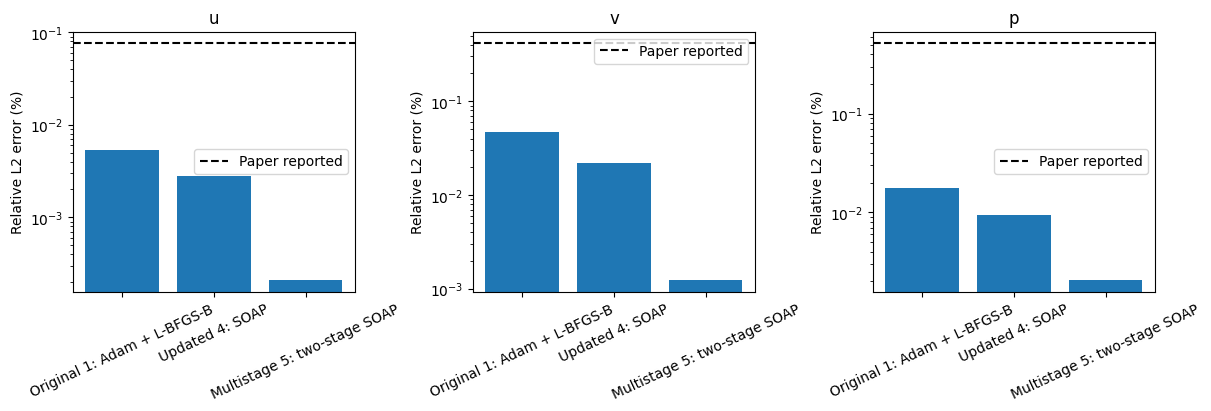

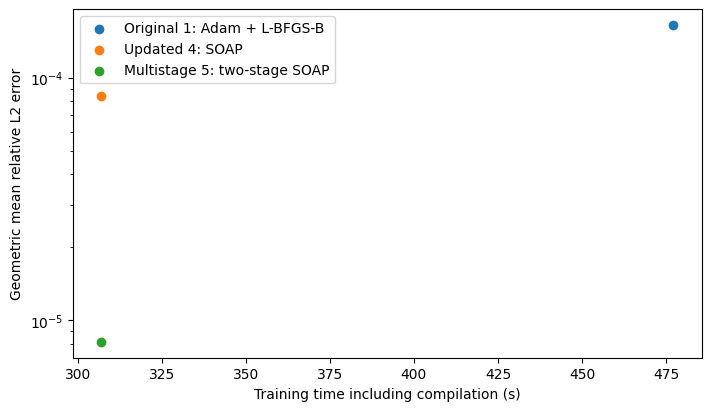

In [ ]:
import pandas as pd
from IPython.display import display

comparison_root = experiment_root

paper_saved = json.loads(
    (comparison_root / '01_paper/final/summary.json').read_text()
)
updated_saved = json.loads(
    (comparison_root / '04_updated/final/summary.json').read_text()
)

# Load both stages; use stage 2's combined-solution errors.
multistage_folder = comparison_root / '05_multistage'
multistage_stages = [
    json.loads(
        (multistage_folder / f'stage{i}/metrics.json').read_text()
    )
    for i in (1, 2)
]

multistage_phases = [
    phase
    for stage in multistage_stages
    for phase in stage['training']
]

metrics = multistage_stages[-1]['metrics']
errors = np.array([
    metrics[f'{field}_relative_l2'] for field in FIELDS
])

multistage_saved = dict(
    method='Two-stage PINN',
    budget=sum(
        int(p.get('updates', p.get('maxiter', p.get('iterations', 0))))
        for p in multistage_phases
    ),
    actual_updates=sum(
        int(p.get('updates', p.get('iterations', 0)))
        for p in multistage_phases
    ),
    seconds=sum(float(p['seconds']) for p in multistage_phases),
    lbfgs_evaluations=sum(
        int(p.get('evaluations', 0)) for p in multistage_phases
    ),
    parameters=sum(
        int(stage['parameters']) for stage in multistage_stages
    ),
    u_percent=100 * float(errors[0]),
    v_percent=100 * float(errors[1]),
    p_percent=100 * float(errors[2]),
    score=float(
        np.exp(np.mean(np.log(np.maximum(errors, 1e-16))))
    ),
    residual_rms=float(
        np.sqrt(np.mean([
            metrics[f'{eq}_rms']**2 for eq in EQUATIONS
        ]))
    ),
    boundary_rms=metrics['boundary_velocity_rms'],
)

paper_saved['method'] = 'Original 1: Adam + L-BFGS-B'
updated_saved['method'] = 'Updated 4: SOAP'
multistage_saved['method'] = 'Multistage 5: two-stage SOAP'

final_table = pd.DataFrame([
    paper_saved,
    updated_saved,
    multistage_saved,
])

reference_seconds = float(updated_saved['seconds'])
final_table['time_over_T'] = (
    final_table['seconds'] / reference_seconds)
final_table['error_reduction_vs_updated'] = (
    float(updated_saved['score']) / final_table['score'])

final_table.to_csv(
    comparison_root / 'final_comparison.csv', index=False)
display(final_table)

stage_updates = [
    sum(
        int(p.get('updates', p.get('iterations', 0)))
        for p in stage['training']
    )
    for stage in multistage_stages
]

print('Compared: paper-reference, updated single-stage, and two-stage PINN.')
print('Multistage time and parameter counts include both stages.')
print(
    f"Actual updates: paper = {paper_saved['actual_updates']}; "
    f"updated = {updated_saved['actual_updates']}; "
    f"multistage = {' + '.join(map(str, stage_updates))} "
    f"= {sum(stage_updates)}."
)
print('Compare actual iterations and training time; iteration costs differ.')

# Published reference values.
reference_setup = json.loads(
    (comparison_root / '01_paper/final/run.json').read_text()
)['settings']
reference_size = (
    reference_setup['layers'],
    reference_setup['width'],
)
reference_errors = PAPER[reference_size]

reference_table = pd.DataFrame([
    dict(
        method='Paper: reported best-of-ten entries',
        u_percent=reference_errors[0],
        v_percent=reference_errors[1],
        p_percent=reference_errors[2],
    )
])
display(reference_table)
reference_table.to_csv(
    comparison_root / 'published_reference.csv', index=False
)

# Field-error comparison.
fig, axes = plt.subplots(
    1, 3, figsize=(12, 4), constrained_layout=True
)
for ax, field in zip(axes, FIELDS):
    ax.bar(
        final_table['method'],
        final_table[f'{field}_percent'],
    )
    ax.axhline(
        reference_table[f'{field}_percent'].iloc[0],
        color='black', linestyle='--', label='Paper reported',
    )
    ax.set(
        yscale='log',
        ylabel='Relative L2 error (%)',
        title=field,
    )
    ax.tick_params(axis='x', labelrotation=25)
    ax.legend()

fig.savefig(comparison_root / 'final_errors.png', dpi=180)
plt.show()

# Accuracy versus total training time.
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
for _, row in final_table.iterrows():
    ax.scatter(
        row['seconds'], row['score'], label=row['method']
    )

ax.set(
    yscale='log',
    xlabel='Training time including compilation (s)',
    ylabel='Geometric mean relative L2 error',
)
ax.legend()
fig.savefig(comparison_root / 'final_time_error.png', dpi=180)
plt.show()